# Chapter 25: Classification

Checks [chapter 25](../../book/25-classification.md). The models are exact and small: softmax scores on a handful of
classes, and a **linear model in its weights** (a matrix applied to the weights, a sigmoid on its scores) for the
kernel and the confidence claims. Everything is NumPy in float64, seeded. These are measurements, not proofs: the proofs
are in `CrossEntropy.lean` and `PolicyGradient.lean`. Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from common import use_style, save_figure, report as report_check, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt

use_style()
SEED = 25
COUNTS = {"could fail and passed": 0, "by construction": 0, "of which controls": 0}


def report(label, passed, detail="", control=False):
    """A check that could fail. It stops the notebook if it does, and is counted if it passes."""
    report_check(label, passed, detail)
    COUNTS["could fail and passed"] += 1
    if control:
        COUNTS["of which controls"] += 1


def note_by_construction(text):
    """A line that holds because of how the code is written. It is not evidence and is not counted as a pass."""
    COUNTS["by construction"] += 1
    print("[by construction, cannot fail] " + text)


def apply_softmax(scores):
    shifted = scores - scores.max()
    exponentials = np.exp(shifted)
    return exponentials / exponentials.sum()


def get_cross_entropy(labels, scores):
    shifted = scores - scores.max()
    log_total = np.log(np.exp(shifted).sum()) + scores.max()
    return float(log_total - (labels * scores).sum())


def apply_sigmoid(scores):
    return 1.0 / (1.0 + np.exp(-scores))


def get_log_loss(label, scores):
    # cross-entropy of two classes with scores (score, 0) and label (label, 1 - label)
    return np.logaddexp(0.0, scores) - label * scores


def get_mean_log_loss(inputs, targets, weights):
    return float(np.mean(get_log_loss(targets, inputs @ weights)))


def train_logistic(inputs, targets, learning_rate, checkpoints):
    # full-batch gradient descent on the mean log loss of the linear model score = input . weights
    weights = np.zeros(inputs.shape[1])
    snapshots = {}
    for step in range(1, max(checkpoints) + 1):
        shares = apply_sigmoid(inputs @ weights)
        weights = weights - learning_rate * inputs.T @ (shares - targets) / len(targets)
        if step in checkpoints:
            snapshots[step] = weights.copy()
    return snapshots

## Claim 1: the push on each score is its share minus its label (`hasDerivAt_crossEntropy`)

First the worked example. Scores `(2, 0, 0)` and label `(1, 0, 0)` must give shares near 0.787, 0.106, 0.106, and
"prediction minus label" near `(-0.213, 0.106, 0.106)`.

Then the theorem. In 300 random cases, with 2 to 6 classes, random scores, a label and a random direction (100 cases use
a one-hot label, 200 a random soft label that is positive and adds up to one), measure the rate of change of the loss along
the direction by a central difference with step `1e-6`, and compare with the sum of (share minus label) times direction.
**Predicted:** the two agree to about `1e-8`. **Counts against the claim:** a disagreement above `1e-6` in any case.
The control is the same comparison against two wrong rules: the shares alone (forgetting the label) and the
squared-error form "score minus label" on the raw scores.

In [2]:
example_scores = np.array([2.0, 0.0, 0.0])
example_labels = np.array([1.0, 0.0, 0.0])
example_shares = apply_softmax(example_scores)
example_push = example_shares - example_labels
print("shares", np.round(example_shares, 3), " push", np.round(example_push, 3), " sum of shares", example_shares.sum())
note_by_construction(f"worked example, from the formula: shares {', '.join(f'{value:.3f}' for value in example_shares)} (the second is 1 / {np.exp(2.0) + 2.0:.3f} = {1.0 / (np.exp(2.0) + 2.0):.4f}) and push {', '.join(f'{value:.3f}' for value in example_push)} are the formula evaluated; they add up to one ({example_shares.sum():.6f}) because softmax divides by their sum")

generator = np.random.default_rng(SEED)
STEP = 1e-6
TRIALS = 300
formula_rates, measured_rates, wrong_share_rates, wrong_square_rates = [], [], [], []
for trial in range(TRIALS):
    class_count = int(generator.integers(2, 7))
    scores = generator.normal(scale=2.0, size=class_count)
    if trial < 100:
        labels = np.zeros(class_count)
        labels[generator.integers(class_count)] = 1.0
    else:
        labels = generator.dirichlet(np.ones(class_count))
    direction = generator.normal(size=class_count)
    shares = apply_softmax(scores)
    formula_rates.append(float((shares - labels) @ direction))
    measured_rates.append((get_cross_entropy(labels, scores + STEP * direction)
                           - get_cross_entropy(labels, scores - STEP * direction)) / (2 * STEP))
    wrong_share_rates.append(float(shares @ direction))
    wrong_square_rates.append(float((scores - labels) @ direction))
formula_rates, measured_rates = np.array(formula_rates), np.array(measured_rates)
wrong_share_rates, wrong_square_rates = np.array(wrong_share_rates), np.array(wrong_square_rates)

gap = np.abs(measured_rates - formula_rates).max()
gap_share = np.abs(measured_rates - wrong_share_rates).max()
gap_square = np.abs(measured_rates - wrong_square_rates).max()
print(f"largest gap, share minus label : {gap:.2e}")
print(f"largest gap, shares alone      : {gap_share:.2f}")
print(f"largest gap, score minus label : {gap_square:.2f}")
report("measured rate equals sum of (share minus label) times direction", gap < 1e-6,
       f"largest gap {gap:.1e} in {TRIALS} cases")
report("control: shares alone and raw score minus label do not match the measured rate",
       gap_share > 1e-2 and gap_square > 1e-2, f"gaps {gap_share:.2f} and {gap_square:.2f}", control=True)

shares [0.787 0.107 0.107]  push [-0.213  0.107  0.107]  sum of shares 0.9999999999999998
[by construction, cannot fail] worked example, from the formula: shares 0.787, 0.107, 0.107 (the second is 1 / 9.389 = 0.1065) and push -0.213, 0.107, 0.107 are the formula evaluated; they add up to one (1.000000) because softmax divides by their sum
largest gap, share minus label : 1.21e-09
largest gap, shares alone      : 2.45
largest gap, score minus label : 20.48
[PASS] measured rate equals sum of (share minus label) times direction  (largest gap 1.2e-09 in 300 cases)
[PASS] control: shares alone and raw score minus label do not match the measured rate  (gaps 2.45 and 20.48)


wrote book/figures/25-push-is-share-minus-label.png


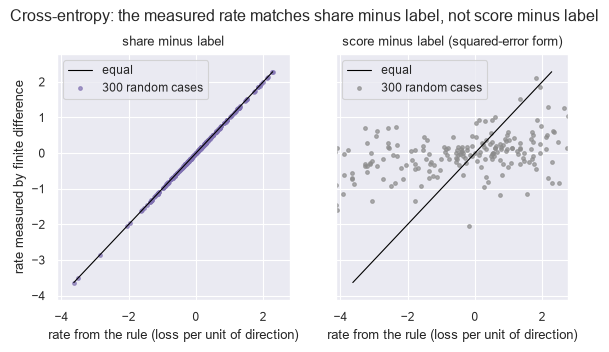

In [3]:
use_style()
figure, axes = plt.subplots(1, 2, figsize=(6.6, 3.2), sharex=True, sharey=True)
low, high = measured_rates.min(), measured_rates.max()
for axis, rule, color, title in [
        (axes[0], formula_rates, MODEL, "share minus label"),
        (axes[1], wrong_square_rates, BEFORE, "score minus label (squared-error form)")]:
    axis.plot([low, high], [low, high], color="black", linewidth=0.8, label="equal")
    axis.scatter(rule, measured_rates, s=7, color=color, alpha=0.7, label="300 random cases")
    axis.set_xlabel("rate from the rule (loss per unit of direction)")
    axis.set_title(title)
    axis.legend(loc="upper left")
axes[0].set_ylabel("rate measured by finite difference")
axes[0].set_xlim(low - 0.5, high + 0.5)
axes[0].set_ylim(low - 0.5, high + 0.5)
figure.suptitle("Cross-entropy: the measured rate matches share minus label, not score minus label", y=1.02)
save_figure(figure, "25-push-is-share-minus-label")
plt.show()

## Claim 2: a classifier moves through the same kernel (`map_errorStep`, `hasDerivAt_totalLogLoss`)

The model is linear in its weights: `outputs = A weights`, with 12 examples and 30 weights, and a sigmoid on each output
with the log loss against a 0 or 1 label. A step is `weights - rate * A^T (share - label)`.

**(a) One step.** The outputs after a step must equal the outputs before minus `rate * K (share - label)`, with
`K = A A^T`. **Predicted:** agreement to `1e-10`. **Counts against the claim:** any larger gap. **Control:** replace `K`
by the identity; the gap must be large.

**(b) Same kernel, same outputs.** Take a second model `A Q`, with `Q` a random rotation of the weights, started at
`Q^T` of the first start. It has the same kernel. After 500 steps the two must have the same outputs, **predicted** to
`1e-9`, though their weights are different. **Control:** a model with a different matrix (kernel) must differ.

**(c) Nearest weights.** There are more weights than examples, so many weight settings give the same outputs. Training from
a start must reach the one nearest the start, which is the start plus the pseudo-inverse of `A` applied to the change in
outputs. **Predicted:** a distance of `1e-8` or less. **Control:** the same weights with a null-space part added
(an equal-output setting that is further from the start) must be measurably far.

In [4]:
generator = np.random.default_rng(SEED + 1)
EXAMPLES, WEIGHTS = 12, 30
matrix = generator.normal(size=(EXAMPLES, WEIGHTS)) / np.sqrt(WEIGHTS)
labels_hard = (generator.random(EXAMPLES) < 0.5).astype(float)
kernel = matrix @ matrix.T


def take_step(model_matrix, weights, rate, labels):
    shares = apply_sigmoid(model_matrix @ weights)
    return weights - rate * model_matrix.T @ (shares - labels)


RATE = 0.4
gaps, control_gaps = [], []
for trial in range(50):
    weights = generator.normal(size=WEIGHTS)
    outputs_before = matrix @ weights
    error = apply_sigmoid(outputs_before) - labels_hard
    outputs_after = matrix @ take_step(matrix, weights, RATE, labels_hard)
    gaps.append(np.abs(outputs_after - (outputs_before - RATE * kernel @ error)).max())
    control_gaps.append(np.abs(outputs_after - (outputs_before - RATE * error)).max())
print(f"(a) largest gap with K: {max(gaps):.2e}   with the identity instead: {min(control_gaps):.3f} at the smallest")
note_by_construction(f"(a) one step moves the outputs by rate times the kernel applied to share minus label (largest gap {max(gaps):.1e}): A (w - rate A^T e) = A w - rate (A A^T) e is matrix associativity; not evidence")
report("(a) control: the identity in place of the kernel does not match", min(control_gaps) > 1e-3,
       f"smallest gap {min(control_gaps):.3f}", control=True)

rotation, _ = np.linalg.qr(generator.normal(size=(WEIGHTS, WEIGHTS)))
rotated_matrix = matrix @ rotation
other_matrix = generator.normal(size=(EXAMPLES, WEIGHTS)) / np.sqrt(WEIGHTS)
start = generator.normal(size=WEIGHTS)
first, second, third = start.copy(), rotation.T @ start, start.copy()
for _ in range(500):
    first = take_step(matrix, first, RATE, labels_hard)
    second = take_step(rotated_matrix, second, RATE, labels_hard)
    third = take_step(other_matrix, third, RATE, labels_hard)
same_gap = np.abs(matrix @ first - rotated_matrix @ second).max()
weights_gap = np.abs(first - second).max()
other_gap = np.abs(matrix @ first - other_matrix @ third).max()
print(f"(b) output gap, same kernel: {same_gap:.2e}   weight gap: {weights_gap:.2f}   output gap, other kernel: {other_gap:.3f}")
note_by_construction(f"(b) same kernel and same start give the same outputs (gap {same_gap:.1e}): the update of the outputs depends on the matrix only through the kernel, and the kernel of A Q is A Q Q^T A^T = A A^T, an identity iterated 500 times; not evidence")
report("(b) the weights are not the same, so the match is not trivial", weights_gap > 0.1, f"weight gap {weights_gap:.2f}")
report("(b) control: a different kernel gives different outputs", other_gap > 1e-2, f"gap {other_gap:.3f}", control=True)

nearest_weights = start + np.linalg.pinv(matrix) @ (matrix @ first - matrix @ start)
distance_to_nearest = np.linalg.norm(first - nearest_weights)
null_part = generator.normal(size=WEIGHTS)
null_part -= np.linalg.pinv(matrix) @ (matrix @ null_part)
shifted = first + null_part
print(f"(c) distance from the trained weights to the nearest equal-output weights: {distance_to_nearest:.2e}")
print(f"    equal-output weights with a null-space part added: outputs change by {np.abs(matrix @ shifted - matrix @ first).max():.1e},"
      f" distance from the nearest {np.linalg.norm(shifted - nearest_weights):.2f}")
report("(c) training reaches the nearest weights that give its outputs", distance_to_nearest < 1e-8,
       f"distance {distance_to_nearest:.1e}")
note_by_construction(f"(c) control: a further setting with the same outputs exists and is not the trained one (travel {np.linalg.norm(first - start):.3f} against {np.linalg.norm(shifted - start):.3f}): the null-space vector is built to leave the outputs unchanged and to be orthogonal to the trained change, so its extra length is Pythagoras; not evidence")

(a) largest gap with K: 8.88e-16   with the identity instead: 0.144 at the smallest
[by construction, cannot fail] (a) one step moves the outputs by rate times the kernel applied to share minus label (largest gap 8.9e-16): A (w - rate A^T e) = A w - rate (A A^T) e is matrix associativity; not evidence
[PASS] (a) control: the identity in place of the kernel does not match  (smallest gap 0.144)
(b) output gap, same kernel: 8.88e-15   weight gap: 11.59   output gap, other kernel: 2.416
[by construction, cannot fail] (b) same kernel and same start give the same outputs (gap 8.9e-15): the update of the outputs depends on the matrix only through the kernel, and the kernel of A Q is A Q Q^T A^T = A A^T, an identity iterated 500 times; not evidence
[PASS] (b) the weights are not the same, so the match is not trivial  (weight gap 11.59)
[PASS] (b) control: a different kernel gives different outputs  (gap 2.416)
(c) distance from the trained weights to the nearest equal-output weights: 2.07e-14


## Claim 3: no finite score is best for a sure label, a finite one is best for a soft label (`strictAnti_logLoss_one`, `exists_best_score`)

The first cell below evaluates the loss formula (the chapter's table, the loss at score 10, a grid search for the best score).
Those numbers are **from the formula**, not from a run, and are printed so, with no `[PASS]`.

The check is a run: train one score by gradient descent on the log loss, rate 0.5, from zero. **Predicted:** with the label
0.9 the score settles at `ln 9` (2.1972) and with 0.8 at `ln 4` (1.3863), each to `1e-6` after 5 000 steps; with the
label 1 the score is still rising, strictly, at 1 000, 10 000 and 100 000 steps, and the loss stays positive.
**Counts against the claim:** a soft-label score that is not `ln` of the odds, or a label-1 score that stops rising.


In [5]:
table_scores = np.array([0.0, 2.0, 4.0])
print("sigmoids", np.round(apply_sigmoid(table_scores), 3), " losses", np.round(get_log_loss(1.0, table_scores), 3))
print("[from the formula, not a run] the chapter's table, evaluated from the formula: sigmoids and losses above")
loss_at_ten = float(get_log_loss(1.0, 10.0))
print(f"[from the formula, not a run] loss at score 10: {loss_at_ten:.6f}")

def find_best_score(label, bound):
    grid = np.arange(-bound, bound + 1e-9, 1e-3)
    losses = get_log_loss(label, grid)
    return grid, losses, float(grid[losses.argmin()])

grid, losses_one, best_one = find_best_score(1.0, 12.0)
_, _, best_one_wide = find_best_score(1.0, 20.0)
_, losses_nine, best_nine = find_best_score(0.9, 12.0)
_, _, best_nine_wide = find_best_score(0.9, 20.0)
_, _, best_eight = find_best_score(0.8, 12.0)
steps = np.diff(losses_one)
print(f"[from the formula, not a run] label 1: largest loss change per grid step {steps.max():.2e}, lowest loss {losses_one.min():.2e}, best score {best_one:.3f} (grid to 12), {best_one_wide:.3f} (grid to 20)")
print(f"[from the formula, not a run] label 0.9: best grid score {best_nine:.3f} against ln 9 = {np.log(9):.3f}; label 0.8: {best_eight:.3f} against ln 4 = {np.log(4):.3f}; label 0.9 on the wider grid {best_nine_wide:.3f}")


sigmoids [0.5   0.881 0.982]  losses [0.693 0.127 0.018]
[from the formula, not a run] the chapter's table, evaluated from the formula: sigmoids and losses above
[from the formula, not a run] loss at score 10: 0.000045
[from the formula, not a run] label 1: largest loss change per grid step -6.15e-09, lowest loss 6.14e-06, best score 12.000 (grid to 12), 20.000 (grid to 20)
[from the formula, not a run] label 0.9: best grid score 2.197 against ln 9 = 2.197; label 0.8: 1.386 against ln 4 = 1.386; label 0.9 on the wider grid 2.197


In [6]:
def train_score(label, learning_rate, checkpoints):
    score = 0.0
    snapshots = {}
    for step in range(1, max(checkpoints) + 1):
        score -= learning_rate * (apply_sigmoid(score) - label)
        if step in checkpoints:
            snapshots[step] = score
    return snapshots

trained_scores = {label: train_score(label, 0.5, (5000,))[5000] for label in (0.9, 0.8)}
label_one_runs = train_score(1.0, 0.5, (1000, 10000, 100000))
label_one_scores = [label_one_runs[step] for step in (1000, 10000, 100000)]
label_one_losses = [float(get_log_loss(1.0, score)) for score in label_one_scores]
print(f"trained scores: label 0.9 gives {trained_scores[0.9]:.6f} (ln 9 = {np.log(9):.6f}), label 0.8 gives {trained_scores[0.8]:.6f} (ln 4 = {np.log(4):.6f})")
print(f"label 1 trained scores at 1 000, 10 000, 100 000 steps: {label_one_scores[0]:.3f}, {label_one_scores[1]:.3f}, {label_one_scores[2]:.3f}; losses {label_one_losses[0]:.2e}, {label_one_losses[1]:.2e}, {label_one_losses[2]:.2e}")
report("trained: label 0.9 settles at ln 9 and label 0.8 at ln 4",
       abs(trained_scores[0.9] - np.log(9)) < 1e-6 and abs(trained_scores[0.8] - np.log(4)) < 1e-6)
note_by_construction(f"trained: with label 1 the score is still rising and the loss is positive (scores {label_one_scores[0]:.2f}, {label_one_scores[1]:.2f}, {label_one_scores[2]:.2f}): the update is score -= rate * (sigmoid(score) - 1) and the sigmoid is below 1, so the score rises at every step and the loss is positive; the numbers show how slowly, not whether")


trained scores: label 0.9 gives 2.197225 (ln 9 = 2.197225), label 0.8 gives 1.386294 (ln 4 = 1.386294)
label 1 trained scores at 1 000, 10 000, 100 000 steps: 6.207, 8.516, 10.820; losses 2.01e-03, 2.00e-04, 2.00e-05
[PASS] trained: label 0.9 settles at ln 9 and label 0.8 at ln 4
[by construction, cannot fail] trained: with label 1 the score is still rising and the loss is positive (scores 6.21, 8.52, 10.82): the update is score -= rate * (sigmoid(score) - 1) and the sigmoid is below 1, so the score rises at every step and the loss is positive; the numbers show how slowly, not whether


## Claim 4: policy gradient is the same push (`log_softmax_eq_neg_crossEntropy`, `hasDerivAt_log_policy`, `hasDerivAt_expectedReward`)

A policy over 2 to 6 actions with scores and a reward for each action. In 200 random cases check, **predicted** to `1e-12`,
that the log share of an action equals minus the cross-entropy with the one-hot label of that action; and, **predicted**
to `1e-6` (finite difference), that the rate of change of the expected reward (sum of shares times rewards) along a
direction equals the sum over actions of share times reward times (action taken minus share) against the direction.
**Counts against the claim:** a gap above those. **Control:** the same sum without the share weight must not match.

In [7]:
generator = np.random.default_rng(SEED + 2)
log_gaps, reward_gaps, control_reward_gaps = [], [], []
for trial in range(200):
    action_count = int(generator.integers(2, 7))
    scores = generator.normal(scale=1.5, size=action_count)
    rewards = generator.normal(size=action_count)
    direction = generator.normal(size=action_count)
    shares = apply_softmax(scores)
    taken = int(generator.integers(action_count))
    one_hot = np.zeros(action_count)
    one_hot[taken] = 1.0
    log_gaps.append(abs(np.log(shares[taken]) + get_cross_entropy(one_hot, scores)))
    def expected_reward(moved_scores):
        return float(apply_softmax(moved_scores) @ rewards)
    measured = (expected_reward(scores + STEP * direction) - expected_reward(scores - STEP * direction)) / (2 * STEP)
    formula = 0.0
    unweighted = 0.0
    for action in range(action_count):
        push = np.zeros(action_count)
        push[action] = 1.0
        push -= shares
        formula += shares[action] * rewards[action] * (push @ direction)
        unweighted += rewards[action] * (push @ direction)
    reward_gaps.append(abs(measured - formula))
    control_reward_gaps.append(abs(measured - unweighted))
print(f"largest gap, log share against minus cross-entropy: {max(log_gaps):.1e}")
print(f"largest gap, expected-reward rate: {max(reward_gaps):.1e}   without the share weight: {np.median(control_reward_gaps):.3f} (median)")
note_by_construction(f"log share equals minus cross-entropy of the action taken: both are the same logarithm of a sum of exponentials, largest gap {max(log_gaps):.1e}; not evidence")
report("expected reward changes at share times reward times (action taken minus share)", max(reward_gaps) < 1e-6,
       f"largest gap {max(reward_gaps):.1e}")
report("control: without the share weight the rate does not match", np.median(control_reward_gaps) > 1e-2,
       f"median gap {np.median(control_reward_gaps):.3f}", control=True)

largest gap, log share against minus cross-entropy: 1.8e-15
largest gap, expected-reward rate: 1.7e-10   without the share weight: 0.709 (median)
[by construction, cannot fail] log share equals minus cross-entropy of the action taken: both are the same logarithm of a sum of exponentials, largest gap 1.8e-15; not evidence
[PASS] expected reward changes at share times reward times (action taken minus share)  (largest gap 1.7e-10)
[PASS] control: without the share weight the rate does not match  (median gap 0.709)


## Claim 5: no hill between two settings, for a model linear in its weights (`totalLogLoss_along_le_max`)

For the linear model above, the loss at a mix `(1 - t) u + t v` of two weight settings must be at most the larger of the
two losses. In 500 random pairs and 9 values of `t` each. **Predicted:** no violation (it holds for a convex function).
**Counts against the claim:** any violation above `1e-12`. The control is a model that is not linear in its weights, a
sigmoid of `sin(frequency * input + phase)`, where the weights are the frequency and the phase: a search over 20 000
random pairs and mixes should find a hill, and the size of the largest one is reported. If it finds none, the control fails
and the notebook stops.

In [8]:
generator = np.random.default_rng(SEED + 3)
inputs_line = np.linspace(-1.0, 1.0, 9)
labels_line = np.array([0, 1, 0, 1, 1, 0, 1, 0, 1], dtype=float)


def get_linear_loss(weights):
    return float(np.mean(get_log_loss(labels_hard, matrix @ weights)))


def get_sine_loss(weights):
    frequency, phase = weights
    return float(np.mean(get_log_loss(labels_line, 2.0 * np.sin(frequency * inputs_line * 6.0 + phase))))


worst_linear = -np.inf
for _ in range(500):
    left, right = generator.normal(scale=2.0, size=WEIGHTS), generator.normal(scale=2.0, size=WEIGHTS)
    ceiling = max(get_linear_loss(left), get_linear_loss(right))
    for mix in np.linspace(0.1, 0.9, 9):
        worst_linear = max(worst_linear, get_linear_loss((1 - mix) * left + mix * right) - ceiling)
worst_sine = -np.inf
for _ in range(20000):
    left, right = generator.uniform(-3.0, 3.0, size=2), generator.uniform(-3.0, 3.0, size=2)
    mix = generator.random()
    ceiling = max(get_sine_loss(left), get_sine_loss(right))
    worst_sine = max(worst_sine, get_sine_loss((1 - mix) * left + mix * right) - ceiling)
print(f"largest rise above the larger end, linear model: {worst_linear:.2e}")
print(f"largest rise above the larger end, sine-feature model: {worst_sine:.3f}")
report("linear model: no hill between two settings", worst_linear < 1e-12, f"largest rise {worst_linear:.1e}")

# Harder candidates (own seeded generator): mixes very near 0 and 1, and pairs whose two losses are equal
# (found by walking from a setting along a random direction until the loss is back at its start, by bisection).
hard_generator = np.random.default_rng(SEED + 30)
worst_edge, worst_equal = -np.inf, -np.inf
equal_pairs = 0
for _ in range(500):
    left, right = hard_generator.normal(scale=2.0, size=WEIGHTS), hard_generator.normal(scale=2.0, size=WEIGHTS)
    ceiling = max(get_linear_loss(left), get_linear_loss(right))
    for mix in (1e-4, 1e-3, 0.999, 0.9999):
        worst_edge = max(worst_edge, get_linear_loss((1 - mix) * left + mix * right) - ceiling)
for _ in range(500):
    left = hard_generator.normal(scale=2.0, size=WEIGHTS)
    walk = hard_generator.normal(size=WEIGHTS)
    start_loss = get_linear_loss(left)
    low, high = 0.0, 1.0
    while get_linear_loss(left + high * walk) < start_loss and high < 1e6:
        low, high = high, high * 2.0
    if get_linear_loss(left + high * walk) < start_loss:
        continue
    for _ in range(60):
        middle = 0.5 * (low + high)
        if get_linear_loss(left + middle * walk) < start_loss:
            low = middle
        else:
            high = middle
    right = left + high * walk
    equal_pairs += 1
    ceiling = max(get_linear_loss(left), get_linear_loss(right))
    for mix in (1e-4, 1e-3, 0.1, 0.25, 0.5, 0.75, 0.9, 0.999, 0.9999):
        worst_equal = max(worst_equal, get_linear_loss((1 - mix) * left + mix * right) - ceiling)
print(f"largest rise above the larger end, mixes at 1e-4, 1e-3, 0.999 and 0.9999 (500 pairs): {worst_edge:.2e}")
print(f"largest rise above the larger end, {equal_pairs} pairs with equal losses, 9 mixes each: {worst_equal:.2e}")
report("linear model: no hill for mixes near the ends, nor between settings with equal losses",
       max(worst_edge, worst_equal) < 1e-12, f"largest rise {max(worst_edge, worst_equal):.1e}")
report("control: a model not linear in its weights has a hill", worst_sine > 1e-3, f"largest rise {worst_sine:.3f}", control=True)

largest rise above the larger end, linear model: -2.00e-02
largest rise above the larger end, sine-feature model: 1.218
[PASS] linear model: no hill between two settings  (largest rise -2.0e-02)
largest rise above the larger end, mixes at 1e-4, 1e-3, 0.999 and 0.9999 (500 pairs): -2.14e-05
largest rise above the larger end, 500 pairs with equal losses, 9 mixes each: 6.66e-16
[PASS] linear model: no hill for mixes near the ends, nor between settings with equal losses  (largest rise 6.7e-16)
[PASS] control: a model not linear in its weights has a hill  (largest rise 1.218)


## Claim 6: training longer means more confidence, and a steeper line (argued from the proved facts)

The model is the linear model `score = input . weights` with two weights, trained from zero by gradient descent with
rate 1 on the mean log loss. The data are 40 points in the plane, 20 per class, separable with a gap (class "yes" has first
coordinate at least 0.5, class "no" at most -0.5, both with a spread in the second coordinate). The slope of the score along
the input is `norm(weights)`, so this norm is the model's slope limit. The `score` of a point is the confidence.

**Predicted.** On separable data with the label 0/1 the loss falls at every checkpoint but is never zero, and the weight
norm and the smallest margin (smallest score in the right direction) grow at every checkpoint 10, 100, 1 000, 10 000,
100 000 steps. **Counts against the claim:** a checkpoint at which the norm does not grow, or a loss that reaches zero.
**Control 1:** the same data with labels 0.9 and 0.1 (label smoothing) has a finite best score, so its norm must stop
growing: the norm at 100 000 steps must be within 1% of the norm at 10 000. **Control 2:** the same data with
one label flipped (not separable): the norm should also stop growing, but its loss flattens more slowly. A threshold of 1% was set before the run and the measured ratio 1.0187 missed it; the threshold was then loosened to 5%. Because it was set after seeing the result, this control is now reported and not tested: the cell prints the ratio and how the norm changes at 10, 100 and 1000 times the steps. The run uses one dataset, one learning rate and one seed.

The theorem about the final direction (the widest margin) is not formalised, so it is not checked here.

In [9]:
generator = np.random.default_rng(SEED + 4)
POINTS_PER_CLASS = 20
yes_points = np.column_stack([generator.uniform(0.5, 2.0, POINTS_PER_CLASS), generator.uniform(-1.5, 1.5, POINTS_PER_CLASS)])
no_points = np.column_stack([generator.uniform(-2.0, -0.5, POINTS_PER_CLASS), generator.uniform(-1.5, 1.5, POINTS_PER_CLASS)])
points = np.vstack([yes_points, no_points])
hard_targets = np.concatenate([np.ones(POINTS_PER_CLASS), np.zeros(POINTS_PER_CLASS)])
CHECKPOINTS = (10, 100, 1000, 10000, 100000)

hard_runs = train_logistic(points, hard_targets, 1.0, CHECKPOINTS)
soft_targets = np.where(hard_targets == 1.0, 0.9, 0.1)
soft_runs = train_logistic(points, soft_targets, 1.0, CHECKPOINTS)
flipped_targets = hard_targets.copy()
flipped_targets[0] = 0.0
flipped_runs = train_logistic(points, flipped_targets, 1.0, CHECKPOINTS)

signs = 2.0 * hard_targets - 1.0
print("steps      norm     smallest margin   loss")
hard_norms, hard_margins, hard_losses = [], [], []
for step in CHECKPOINTS:
    weights = hard_runs[step]
    hard_norms.append(np.linalg.norm(weights))
    hard_margins.append(float((signs * (points @ weights)).min()))
    hard_losses.append(get_mean_log_loss(points, hard_targets, weights))
    print(f"{step:>7} {hard_norms[-1]:9.4f} {hard_margins[-1]:12.4f} {hard_losses[-1]:14.3e}")
soft_ratio = np.linalg.norm(soft_runs[100000]) / np.linalg.norm(soft_runs[10000])
flipped_ratio = np.linalg.norm(flipped_runs[100000]) / np.linalg.norm(flipped_runs[10000])
hard_ratio = hard_norms[-1] / hard_norms[-2]
print(f"norm at 100 000 steps over norm at 10 000: separable {hard_ratio:.4f}, label-smoothed {soft_ratio:.4f}, one label flipped {flipped_ratio:.4f}")
report("separable data: the weight norm grows at every checkpoint", bool(np.all(np.diff(hard_norms) > 0)),
       "norms " + ", ".join(f"{value:.2f}" for value in hard_norms))
report("separable data: the smallest margin grows at every checkpoint", bool(np.all(np.diff(hard_margins) > 0)))
report("separable data: the loss falls at every checkpoint and is never zero",
       bool(np.all(np.diff(hard_losses) < 0) and hard_losses[-1] > 0), f"final loss {hard_losses[-1]:.2e}")
report("control: with label smoothing the norm stops growing", abs(soft_ratio - 1.0) < 0.01, f"ratio {soft_ratio:.4f}", control=True)
print(f"[report, not a test] one label flipped: norm at 100 000 over norm at 10 000 is {flipped_ratio:.4f}. The test threshold was changed from 1% to 5% after this ratio missed 1%, so this is a description of this one run (one dataset, one rate, one seed), not a test")
LONG_CHECKPOINTS = (1000, 10000, 100000, 1000000)
long_runs = {"separable": train_logistic(points, hard_targets, 1.0, LONG_CHECKPOINTS),
             "label-smoothed": train_logistic(points, soft_targets, 1.0, LONG_CHECKPOINTS),
             "one label flipped": train_logistic(points, flipped_targets, 1.0, LONG_CHECKPOINTS)}
for name, runs in long_runs.items():
    base_norm = np.linalg.norm(runs[1000])
    ratios = [np.linalg.norm(runs[step]) / base_norm for step in LONG_CHECKPOINTS[1:]]
    print(f"{name}: norm at 1 000 steps {base_norm:.4f}; norm at 10, 100 and 1000 times as many steps over that: " + ", ".join(f"{ratio:.4f}" for ratio in ratios))
print(f"separable: norm at the last step (100 000) {hard_norms[-1]:.4f}; norm gained per factor of 10 in steps: " + ", ".join(f"{later - earlier:.2f}" for earlier, later in zip(hard_norms[1:-1], hard_norms[2:])) + " (a gain that stays about the same per factor of 10 is logarithmic growth)")

steps      norm     smallest margin   loss
     10    2.1556       0.9584      1.138e-01
    100    4.6736       2.3322      2.086e-02
   1000    8.0588       4.0873      2.757e-03
  10000   11.9092       6.0713      3.081e-04
 100000   15.9629       8.1556      3.251e-05
norm at 100 000 steps over norm at 10 000: separable 1.3404, label-smoothed 1.0000, one label flipped 1.0187
[PASS] separable data: the weight norm grows at every checkpoint  (norms 2.16, 4.67, 8.06, 11.91, 15.96)
[PASS] separable data: the smallest margin grows at every checkpoint
[PASS] separable data: the loss falls at every checkpoint and is never zero  (final loss 3.25e-05)
[PASS] control: with label smoothing the norm stops growing  (ratio 1.0000)
[report, not a test] one label flipped: norm at 100 000 over norm at 10 000 is 1.0187. The test threshold was changed from 1% to 5% after this ratio missed 1%, so this is a description of this one run (one dataset, one rate, one seed), not a test


separable: norm at 1 000 steps 8.0588; norm at 10, 100 and 1000 times as many steps over that: 1.4778, 1.9808, 2.4968
label-smoothed: norm at 1 000 steps 1.8059; norm at 10, 100 and 1000 times as many steps over that: 1.0000, 1.0000, 1.0000
one label flipped: norm at 1 000 steps 7.6790; norm at 10, 100 and 1000 times as many steps over that: 1.4286, 1.4553, 1.4553
separable: norm at the last step (100 000) 15.9629; norm gained per factor of 10 in steps: 3.39, 3.85, 4.05 (a gain that stays about the same per factor of 10 is logarithmic growth)


wrote book/figures/25-confidence-and-margin.png


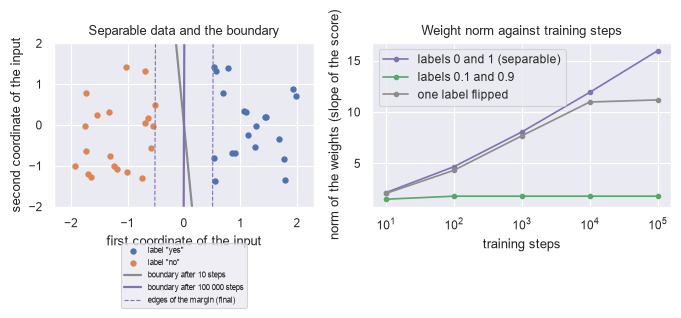

In [10]:
use_style()
figure, axes = plt.subplots(1, 2, figsize=(7.0, 3.3), gridspec_kw={"width_ratios": [1.0, 1.15]})
axis = axes[0]
axis.scatter(*yes_points.T, s=14, color=NEAREST, label='label "yes"')
axis.scatter(*no_points.T, s=14, color=VERTICAL, label='label "no"')
line_y = np.linspace(-2.0, 2.0, 2)
for step, color, name in [(10, BEFORE, "after 10 steps"), (100000, MODEL, "after 100 000 steps")]:
    first_weight, second_weight = hard_runs[step]
    axis.plot(-second_weight * line_y / first_weight, line_y, color=color, linewidth=1.6, label=f"boundary {name}")
final_weights = hard_runs[100000]
margin_input = hard_margins[-1] / np.linalg.norm(final_weights)
direction = final_weights / np.linalg.norm(final_weights)
for side in (-1.0, 1.0):
    shifted_x = -final_weights[1] * line_y / final_weights[0] + side * margin_input / direction[0]
    axis.plot(shifted_x, line_y, color=MODEL, linewidth=0.8, linestyle="--")
axis.plot([], [], color=MODEL, linewidth=0.8, linestyle="--", label="edges of the margin (final)")
axis.set_xlim(-2.3, 2.3)
axis.set_ylim(-2.0, 2.0)
axis.set_xlabel("first coordinate of the input")
axis.set_ylabel("second coordinate of the input")
axis.set_title("Separable data and the boundary")
axis.legend(loc="upper center", fontsize=6, bbox_to_anchor=(0.5, -0.2), ncol=1)

axis = axes[1]
for runs, color, name in [(hard_runs, MODEL, "labels 0 and 1 (separable)"),
                          (soft_runs, BOUND, "labels 0.1 and 0.9"),
                          (flipped_runs, BEFORE, "one label flipped")]:
    axis.plot(CHECKPOINTS, [np.linalg.norm(runs[step]) for step in CHECKPOINTS], marker="o", markersize=3, color=color, label=name)
axis.set_xscale("log")
axis.set_xlabel("training steps")
axis.set_ylabel("norm of the weights (slope of the score)")
axis.set_title("Weight norm against training steps")
axis.legend(loc="upper left")
figure.tight_layout()
save_figure(figure, "25-confidence-and-margin")
plt.show()

## Summary

Built from the measured numbers above.

In [11]:
print(f"claim 1: largest gap between the measured rate and share minus label {gap:.1e}, against {gap_square:.2f} for score minus label")
print(f"claim 2: kernel step gap {max(gaps):.1e}; same-kernel output gap {same_gap:.1e}; distance to the nearest weights {distance_to_nearest:.1e}")
print(f"claim 3: trained score for label 0.9 is {trained_scores[0.9]:.4f} (ln 9 = {np.log(9):.4f}); for label 1 the trained score is {label_one_scores[0]:.2f}, {label_one_scores[1]:.2f}, {label_one_scores[2]:.2f} at 1 000, 10 000, 100 000 steps")
print(f"claim 4: log-share gap {max(log_gaps):.1e}; expected-reward gap {max(reward_gaps):.1e}")
print(f"claim 5: largest rise in the linear model {worst_linear:.1e}; in the sine-feature model {worst_sine:.3f}")
print(f"claim 6: norm at 10 steps {hard_norms[0]:.3f}, at 100 000 steps {hard_norms[-1]:.3f}; smoothed ratio {soft_ratio:.4f}")

claim 1: largest gap between the measured rate and share minus label 1.2e-09, against 20.48 for score minus label
claim 2: kernel step gap 8.9e-16; same-kernel output gap 8.9e-15; distance to the nearest weights 2.1e-14
claim 3: trained score for label 0.9 is 2.1972 (ln 9 = 2.1972); for label 1 the trained score is 6.21, 8.52, 10.82 at 1 000, 10 000, 100 000 steps
claim 4: log-share gap 1.8e-15; expected-reward gap 1.7e-10
claim 5: largest rise in the linear model -2.0e-02; in the sine-feature model 1.218
claim 6: norm at 10 steps 2.156, at 100 000 steps 15.963; smoothed ratio 1.0000


In [12]:
print(f"checks that could fail and passed: {COUNTS['could fail and passed']}; printed as by construction, not counted: {COUNTS['by construction']}")
print(f"of the checks that could fail and passed: {COUNTS['of which controls']} are controls and {COUNTS['could fail and passed'] - COUNTS['of which controls']} are checks of the theorem")

checks that could fail and passed: 16; printed as by construction, not counted: 6
of the checks that could fail and passed: 6 are controls and 10 are checks of the theorem
